# Facades: attach rules to a building, then inspect resolved openings

This lesson needs a **local EPW**, but no EnergyPlus run. It uses illustrative components from `examples/building.py` to construct a complete building. For national UBEM, retain the source and confidence of each facade assumption: a default WWR is an archetype assumption, not an observation of every elevation.

`GeometrySpec` owns the physical facade catalogue. `FacadeSpec` is a separate reusable set of opening and shading rules. `BuildingSpec` combines these with climate, envelope, airflow and use, validating that referenced facade IDs and storeys exist. Geometry resolution then checks whether the requested openings fit the walls.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


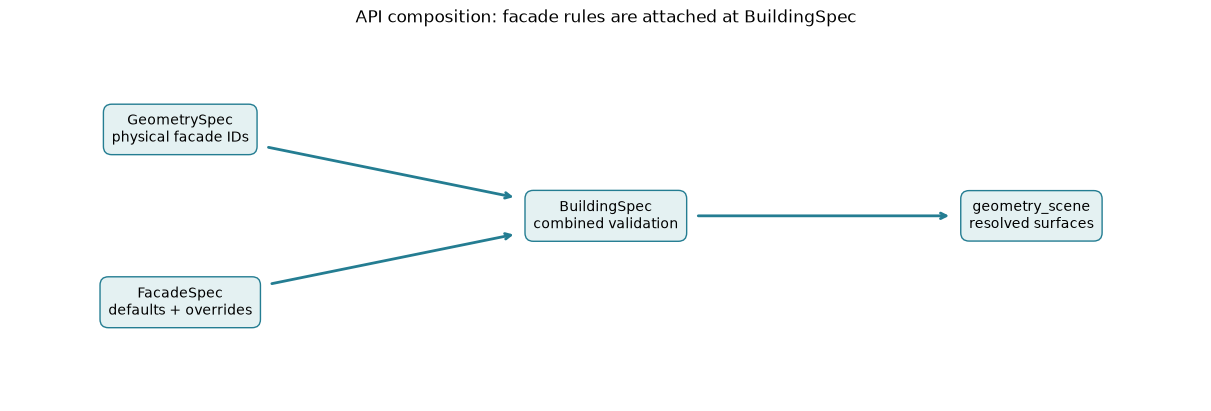

In [2]:
from demo.support.common import flow
flow(["GeometrySpec\nphysical facade IDs", "FacadeSpec\ndefaults + overrides", "BuildingSpec\ncombined validation", "geometry_scene\nresolved surfaces"],
     "API composition: facade rules are attached at BuildingSpec", converge=True)

## 1. Discover physical facade IDs

Never infer IDs from a compass direction: they identify original part/ring/edge ownership. The catalogue reports azimuth clockwise from north after `orientation_deg` is applied. Its edge coordinates remain in the input frame; below we rotate the plan clockwise by the same angle for a north-up drawing. Changing the footprint topology can change the catalogue, so revalidate overrides after a geometry change.

,facade_id,part_id,start_m,end_m,length_m,azimuth_deg,storeys,storey_elevations_m
0,main.r0.e0,main,"(0.0, 0.0)","(30.0, 0.0)",30.0,205.0,"(0, 1, 2)","(0.0, 3.0, 6.0, 9.0)"
1,main.r0.e1,main,"(30.0, 0.0)","(30.0, 20.0)",20.0,115.0,"(0, 1, 2)","(0.0, 3.0, 6.0, 9.0)"
2,main.r0.e2,main,"(30.0, 20.0)","(0.0, 20.0)",30.0,25.0,"(0, 1, 2)","(0.0, 3.0, 6.0, 9.0)"
3,main.r0.e3,main,"(0.0, 20.0)","(0.0, 0.0)",20.0,295.0,"(0, 1, 2)","(0.0, 3.0, 6.0, 9.0)"


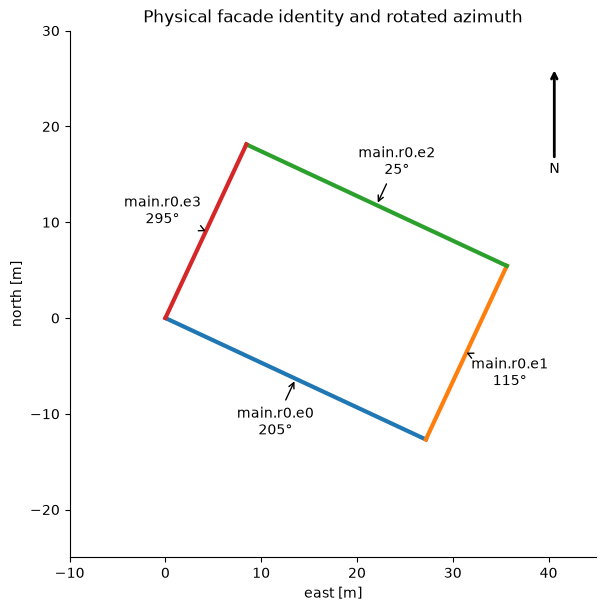

In [3]:
g = geometry(orientation_deg=25)
facades = g.facades()
table([asdict(f) for f in facades])
fid = facades[0].facade_id
angle = np.deg2rad(g.orientation_deg)
rotation = np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]])
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
for f in facades:
    edge = np.array([f.start_m, f.end_m]) @ rotation.T
    ax.plot(edge[:, 0], edge[:, 1], lw=3)
    center = edge.mean(axis=0)
    az = np.deg2rad(f.azimuth_deg)
    outward = np.array([np.sin(az), np.cos(az)])
    label = center + 5 * outward
    ax.annotate(f"{f.facade_id}\n{f.azimuth_deg:.0f}°", xy=center, xytext=label,
                ha="center", va="center", arrowprops=dict(arrowstyle="->"))
ax.annotate("N", xy=(.92,.93), xytext=(.92,.73), xycoords="axes fraction",
            ha="center", arrowprops=dict(arrowstyle="->", lw=2))
ax.set(xlim=(-10,45), ylim=(-25,30), aspect="equal", xlabel="east [m]", ylabel="north [m]",
       title="Physical facade identity and rotated azimuth")
plt.show(); plt.close(fig)

## 2. Attach FacadeSpec to an existing or new building

`b.updated(facade=facade_spec)` replaces the **whole facade specification** and returns a validated building; it does not mutate `b`. To change just one field while preserving glazing, overrides and shading, nest the update: `b.updated(facade=b.facade.updated(default_wwr=.30))`.

The full constructor below supplies every required component. The demo factory supplies explicit illustrative envelope/operation values and the local weather identity; they are not hidden package defaults. Replacing `geometry` first is safe here because the baseline has no ID-specific overrides.

In [4]:
b = building().updated(geometry=g)
baseline_json = b.model_dump_json()
facade_spec = FacadeSpec(
    default_wwr=.25,
    glazing=GlazingSpec(u_value_w_m2k=1.4, solar_heat_gain_coefficient=.55),
    overrides=(FacadeOverride(facade_id=fid, wwr=.35),
               FacadeOverride(facade_id=fid, storey=0, wwr=.15)),
)
updated_building = b.updated(facade=facade_spec)
nested_update = b.updated(facade=b.facade.updated(default_wwr=.30))
assert nested_update.facade.glazing == b.facade.glazing
climate, envelope, airflow, use = b.climate, b.envelope, b.airflow, b.use
new_building = BuildingSpec(identifier="facade-example", geometry=g, facade=facade_spec,
                            climate=climate, envelope=envelope, airflow=airflow, use=use)
assert new_building.facade == updated_building.facade
assert b.model_dump_json() == baseline_json

## 3. Resolve override precedence field by field

For each field: **default → whole-facade override → facade/storey override**. `None` inherits the preceding value. Storeys are zero-based. The heatmap below evaluates `wwr_for` on the actual catalogue; it shows requested fractions, before opening geometry is resolved. A dimensions-based layout instead controls opening dimensions and does not promise the same realized WWR.

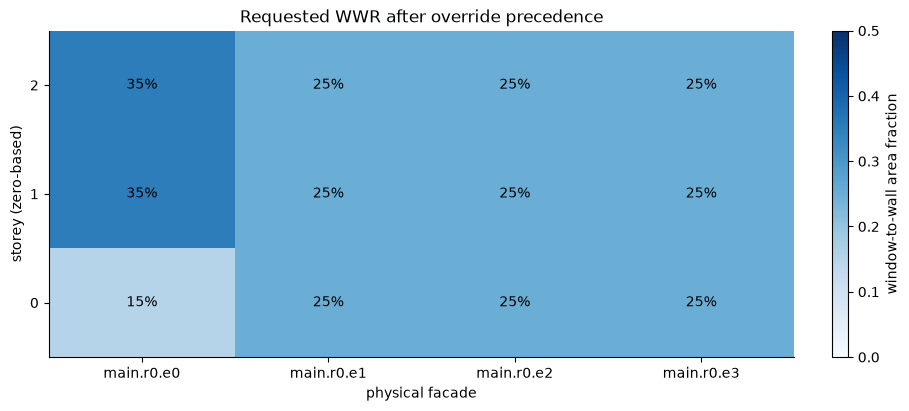

In [5]:
storeys = sorted({s for f in facades for s in f.storeys})
wwr = np.array([[facade_spec.wwr_for(f.facade_id, s) for f in facades] for s in storeys])
assert wwr[0,0] == .15 and wwr[1,0] == .35 and wwr[0,1] == .25
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
im = ax.imshow(wwr, origin="lower", vmin=0, vmax=.5, cmap="Blues", aspect="auto")
for row in range(len(storeys)):
    for col in range(len(facades)):
        ax.text(col,row,f"{wwr[row,col]:.0%}",ha="center",va="center")
ax.set_xticks(range(len(facades)), [f.facade_id for f in facades])
ax.set_yticks(range(len(storeys)),storeys)
ax.set(xlabel="physical facade", ylabel="storey (zero-based)", title="Requested WWR after override precedence")
fig.colorbar(im, ax=ax, label="window-to-wall area fraction")
plt.show(); plt.close(fig)

## 4. Compare resolved elevations and attached shading

To compare opening patterns fairly, keep the same unrotated outline, glazing and WWR policy in all four panels. These are actual `geometry_scene` surfaces projected onto the first facade, with a shared metric scale. Blue polygons are emitted thermal panes; they may subdivide a logical window. Orange lines are the elevation projections of explicit shading (depth is clearer in the widget).

Scaled mode makes area-scaled openings; WWR mode distributes repeated openings; dimensions mode specifies width, height and centre spacing. The final panel adds recess, overhang and balcony shading to WWR mode. These shade surfaces do not add conditioned floor area. Shading geometry and an aggregate solar shading factor represent different inputs; avoid counting the same obstruction twice.

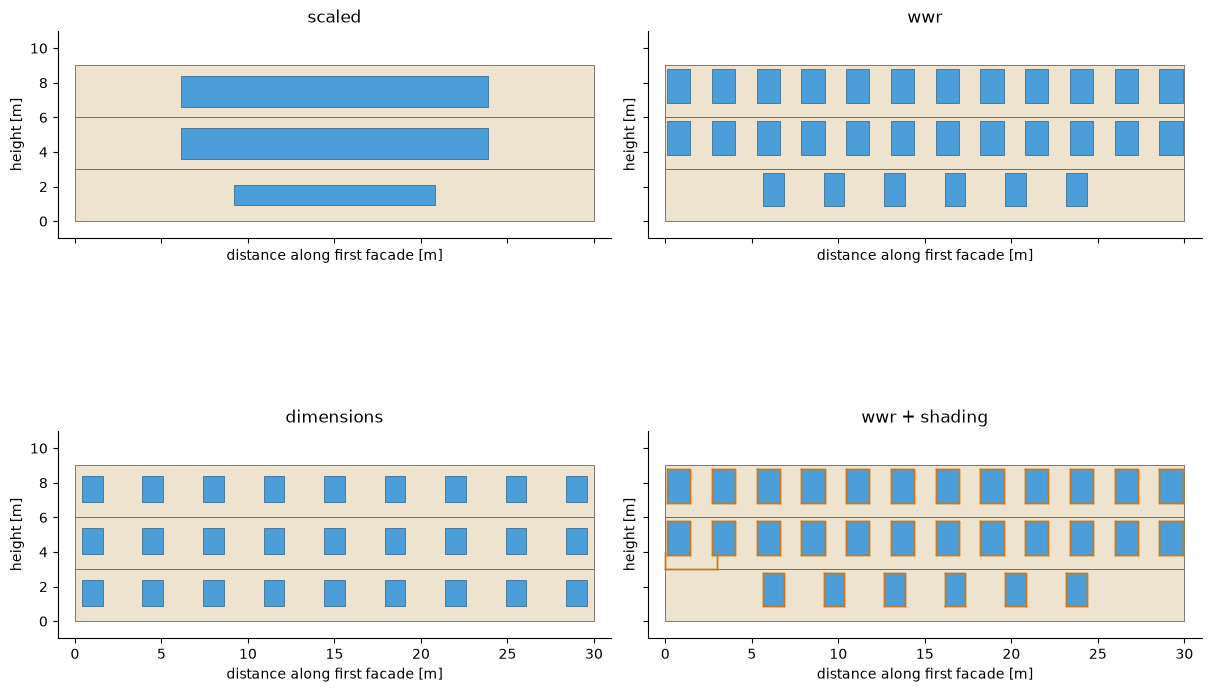

,layout,logical_windows,thermal_panes,shade_surfaces
0,scaled,12,12,0
1,wwr,93,93,0
2,dimensions,90,90,0
3,wwr + shading,93,93,375


In [6]:
comparison_geometry = g.updated(orientation_deg=0)
layouts = {
    "scaled": WindowLayoutSpec(mode="scaled"),
    "wwr": WindowLayoutSpec(mode="wwr"),
    "dimensions": WindowLayoutSpec(mode="dimensions", window_width_m=1.2,
                                    window_height_m=1.5, center_spacing_m=3.5, sill_height_ratio=.3),
}
shaded = facade_spec.updated(layout=layouts["wwr"], reveal_depth_m=.12,
    overhang=OverhangSpec(depth_m=.6),
    balconies=(BalconySpec(facade_id=fid, storeys=(1,), width_m=3, depth_m=1.2,
                          side_screen_height_m=1),))
cases = {mode:facade_spec.updated(layout=layout) for mode,layout in layouts.items()}
cases["wwr + shading"] = shaded
fig, axes = plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True,layout="constrained")
rows = []
def vertices(surface):
    return np.array([[v["vertex_x_coordinate"],v["vertex_y_coordinate"],v["vertex_z_coordinate"]]
                     for v in surface["vertices"]])
for ax, (name, specification) in zip(axes.flat, cases.items()):
    scene, report = geometry_scene(comparison_geometry, facade=specification)
    parents = {key for key, meta in report["surfaces"].items() if meta.get("facade_id")==fid}
    for key in parents:
        v = vertices(scene["BuildingSurface:Detailed"][key])
        ax.fill(v[:,0],v[:,2],facecolor="#ede3cf",edgecolor="#666666",lw=.6)
    for surface in scene.get("FenestrationSurface:Detailed",{}).values():
        if surface["building_surface_name"] in parents:
            v = vertices(surface)
            ax.fill(v[:,0],v[:,2],facecolor="#4c9ed9",edgecolor="#285e85",lw=.5)
    for surface in scene.get("Shading:Building:Detailed",{}).values():
        v = vertices(surface)
        if v[:,1].max() <= .2:
            v = np.vstack([v,v[0]])
            ax.plot(v[:,0],v[:,2],color="#c87821",lw=1)
    ax.set(title=name, aspect="equal", xlabel="distance along first facade [m]", ylabel="height [m]",
           xlim=(-1,31),ylim=(-1,11))
    rows.append({"layout":name,"logical_windows":report["logical_window_count"],
                 "thermal_panes":report["thermal_pane_count"],
                 "shade_surfaces":len(scene.get("Shading:Building:Detailed",{}))})
plt.show(); plt.close(fig)
table(rows)
assert rows[-1]["shade_surfaces"] > 0

## 5. Preview is transient; building attachment persists

`g.widget(facade=shaded)` returns a widget using facade rules **for that view only**; `g` never acquires a facade field. By contrast, `updated_building = b.updated(facade=shaded)` stores the rules on a new complete specification. `updated_building.widget()` therefore needs no facade argument. The widget below embeds in the notebook: orbit to see shading depth, select surfaces and inspect their ownership. Re-run this cell with a live kernel to restore interaction; static elevations remain readable in saved notebooks.

In [7]:
transient_preview = g.widget(facade=shaded, height=550)
updated_building = b.updated(facade=shaded)
assert updated_building.facade == shaded
assert b.model_dump_json() == baseline_json
widget = updated_building.widget(height=550)
display(widget)  # Display one view; keep the handle without a second implicit display.

## 6. Catch invalid assignments before a stock batch

Duplicate facade/storey overrides are rejected by `FacadeSpec` itself. Unknown IDs and nonexistent storeys require the geometry catalogue and are rejected when the facade is attached to `BuildingSpec`. Successful schema validation still does not establish geometric feasibility: resolve the building before dispatching an annual simulation. In national UBEM, record these rejected cases and their input identities instead of silently substituting defaults.

In [8]:
from pydantic import ValidationError
failures = {}
for label, override in {
    "unknown facade": FacadeOverride(facade_id="missing", wwr=.2),
    "nonexistent storey": FacadeOverride(facade_id=fid, storey=99, wwr=.2),
}.items():
    try:
        b.updated(facade=facade_spec.updated(overrides=(override,)))
    except ValidationError as exc:
        failures[label] = exc.errors()[0]["msg"]
    else:
        raise AssertionError(f"Expected rejection: {label}")
try:
    repeated = FacadeOverride(facade_id=fid, storey=0, wwr=.2)
    facade_spec.updated(overrides=(repeated,repeated))
except ValidationError as exc:
    failures["duplicate override"] = exc.errors()[0]["msg"]
else:
    raise AssertionError("Expected duplicate rejection")
assert len(failures)==3 and b.model_dump_json()==baseline_json
table(failures)

,field,value
0,unknown facade,"Value error, Override references unknown facad..."
1,nonexistent storey,"Value error, Override references nonexistent s..."
2,duplicate override,"Value error, Duplicate facade/storey overrides"


,field,value
0,unknown facade,"Value error, Override references unknown facad..."
1,nonexistent storey,"Value error, Override references nonexistent s..."
2,duplicate override,"Value error, Duplicate facade/storey overrides"
